In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

DATA_DIR = Path(r"D:\F20DL CW UG\Insurance-Fraud-Detection\Insurance-Fraud-Detection")
RESULTS = Path("../results/images")

CLASSES = ["Fraud", "Non-Fraud"]

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

tf.keras.utils.set_random_seed(SEED) # Sets the random seed for TensorFlow (reproducibility of results)

print("TensorFlow version:", tf.__version__)
print("Dataset found:", DATA_DIR.exists())
print("GPU available:", tf.config.list_physical_devices("GPU")) # checks whether TensorFlow can use graphics card to train faster

TensorFlow version: 2.21.0
Dataset found: True
GPU available: []


In [2]:
from sklearn.model_selection import train_test_split

## Function to list all image files in a given folder
def list_images(folder):
    files = []
    for f in folder.iterdir(): # loops over all files in folder
        if f.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            files.append(str(f))
    return files

# Function to get the paths and labels of images in a given split (train/test)
def get_paths_and_labels(split):
    paths = []
    labels = []
    for c in CLASSES: 
        files = list_images(DATA_DIR / split / c) #
        paths += files
        if c == "Fraud":
            labels += [1] * len(files) # adds a label of 1 for each fraud image
        else:
            labels += [0] * len(files) # adds a label of 0 for each non-fraud image
    return paths, labels

train_paths, train_labels = get_paths_and_labels("train") # gets the paths and labels for the training set
test_paths, test_labels = get_paths_and_labels("test") # gets the paths and labels for the test set

# Splits the training set into a training and validation set
train_paths, val_paths, train_labels, val_labels = train_test_split(
    train_paths, train_labels,
    test_size=0.15, # 15% of the training data will be used for validation
    stratify=train_labels, # ensures the same proportion of fraud and non-fraud images in both sets
    random_state=SEED # sets the random seed for reproducibility
)

# Prints the number of images and fraud cases in each set
print("Train:     ", len(train_paths), "images,", sum(train_labels), "fraud")
print("Validation:", len(val_paths), "images,", sum(val_labels), "fraud")
print("Test:      ", len(test_paths), "images,", sum(test_labels), "fraud")

Train:      4420 images, 170 fraud
Validation: 780 images, 30 fraud
Test:       1416 images, 93 fraud


In [3]:
# Function to load and resize an image given its path and label
def load_and_resize(path, label):
    img = tf.io.read_file(path) # Read the image file
    img = tf.io.decode_image(img, channels=3, expand_animations=False) # Decode the image
    img = tf.image.resize(img, IMG_SIZE) # Resize the image
    img = tf.cast(img, tf.uint8) # Cast the image to uint8
    return img, label

# Function to normalise an image given its label
def normalise(img, label):
    img = tf.cast(img, tf.float32) / 255.0 # Normalise the image to [0, 1]
    return img, label

# Function to create a TensorFlow dataset from image paths and labels
def make_dataset(paths, labels, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels)) # creates a dataset
    ds = ds.map(load_and_resize, num_parallel_calls=tf.data.AUTOTUNE) # applies the load_and_resize function in parallel
    ds = ds.cache() # caches the dataset in memory for faster access

    # If shuffle is True, shuffle the dataset with a buffer size equal to the number of paths
    if shuffle:
        ds = ds.shuffle(len(paths), seed=SEED) 
    ds = ds.map(normalise) 
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(train_paths, train_labels, shuffle=True) # creates the training dataset
val_ds = make_dataset(val_paths, val_labels) # creates the validation dataset
test_ds = make_dataset(test_paths, test_labels) # creates the test dataset

# Prints the shape of one batch of images and labels, and the range of pixel values
images, labels = next(iter(train_ds))
print("One batch of images:", images.shape)
print("One batch of labels:", labels.shape)
print("Pixel values from", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))

One batch of images: (32, 128, 128, 3)
One batch of labels: (32,)
Pixel values from 0.0 to 1.0


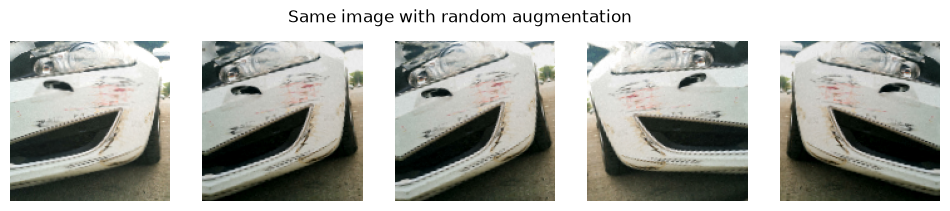

Class weights: {0: 0.52, 1: 13.0}


In [9]:
from tensorflow.keras import layers

# Data augmentation pipeline using Keras Sequential API
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"), # randomly flips the image horizontally
    layers.RandomRotation(0.05), # randomly rotates the image by up to 5% of 360 degrees
    layers.RandomBrightness(0.1, value_range=(0, 1)), # randomly adjusts the brightness of the image by up to 10%
], name="augmentation")

sample_img = images[0] # Select a sample image from the dataset
plt.figure(figsize=(12, 2.3)) # Create a figure with a specific size
for i in range(5): # Loop to create 5 augmented versions of the sample image
    aug = data_augmentation(tf.expand_dims(sample_img, 0), training=True) # Applies augmentation
    plt.subplot(1, 5, i + 1) # Create a subplot for each augmented image
    plt.imshow(aug[0]) 
    plt.axis("off")
plt.suptitle("Same image with random augmentation") 
plt.savefig(RESULTS / "augmentation_examples.png", dpi=150, bbox_inches="tight")
plt.show()

# Calculate class weights to handle class imbalance
n_total = len(train_labels)
n_fraud = sum(train_labels)
n_non_fraud = n_total - n_fraud
class_weight = {  # calculates the class weights for the two classes (0: non-fraud, 1: fraud)
    0: n_total / (2 * n_non_fraud),
    1: n_total / (2 * n_fraud),
}
print("Class weights:", class_weight)